In [13]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [14]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [15]:
len(words)

32033

In [16]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [17]:
block_size = 3

def build_dataset(words):  
    X, Y = [], []
  
    for w in words:
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [18]:
n_embd = 10
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),             generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                       generator=g) * 0

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros(1, n_hidden)
bnstd_running = torch.ones(1, n_hidden)
bnmean_running = torch.zeros(1, n_hidden)

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad=True

12097


In [ ]:
max_steps = 200000
batch_size = 32
track_size_print = 10000
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xtr[ix]]
    embcat = emb.view(emb.shape[0], -1)
    # linear layer
    hpreact = embcat @ W1 # + b1

    # BatchNorm layer
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    # Non-linearity
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % track_size_print == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break

      0/ 200000: 3.2831
  10000/ 200000: 2.1532
  20000/ 200000: 2.0893
  30000/ 200000: 2.4084
  40000/ 200000: 2.5807
  50000/ 200000: 1.5771
  60000/ 200000: 2.1084
  70000/ 200000: 2.0737
  80000/ 200000: 2.1754
  90000/ 200000: 1.7735
 100000/ 200000: 2.2146
 110000/ 200000: 2.0881
 120000/ 200000: 2.0608
 130000/ 200000: 2.0611
 140000/ 200000: 2.0959
 150000/ 200000: 2.2074
 160000/ 200000: 2.3113
 170000/ 200000: 1.9983
 180000/ 200000: 2.1113
 190000/ 200000: 1.8127


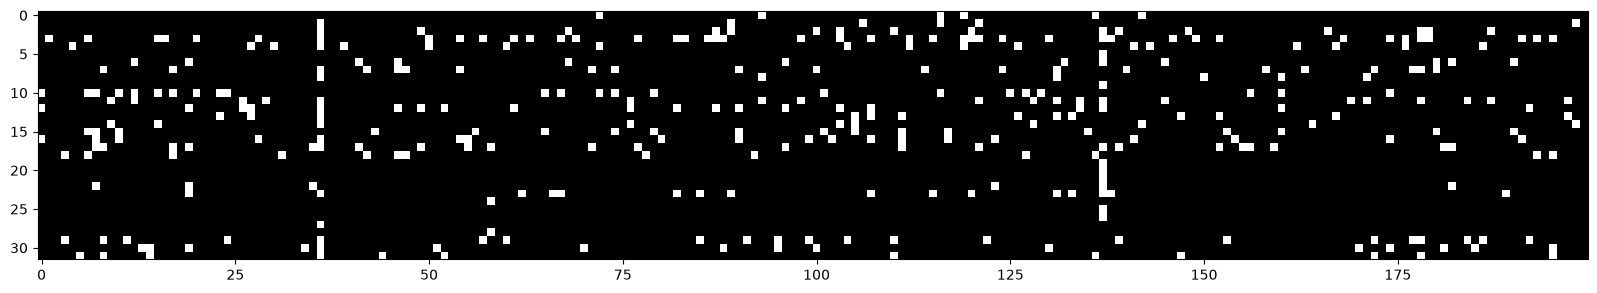

In [20]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

(array([480., 208., 166., 160., 125., 114., 123.,  87., 101.,  79.,  84.,
         85.,  99.,  85.,  88., 107., 144.,  86., 128.,  97.,  96., 101.,
        114.,  95., 187., 146., 116., 142.,  99.,  92.,  94.,  96.,  80.,
         94.,  74.,  82.,  97.,  88.,  89.,  97., 101.,  88., 123., 156.,
        116., 101., 153., 190., 232., 415.]),
 array([-9.99957979e-01, -9.59958894e-01, -9.19959810e-01, -8.79960725e-01,
        -8.39961641e-01, -7.99962556e-01, -7.59963472e-01, -7.19964387e-01,
        -6.79965303e-01, -6.39966218e-01, -5.99967134e-01, -5.59968050e-01,
        -5.19968965e-01, -4.79969881e-01, -4.39970796e-01, -3.99971712e-01,
        -3.59972627e-01, -3.19973543e-01, -2.79974458e-01, -2.39975374e-01,
        -1.99976289e-01, -1.59977205e-01, -1.19978120e-01, -7.99790359e-02,
        -3.99799514e-02,  1.91330910e-05,  4.00182176e-02,  8.00173020e-02,
         1.20016387e-01,  1.60015471e-01,  2.00014555e-01,  2.40013640e-01,
         2.80012724e-01,  3.20011809e-01,  3.60010

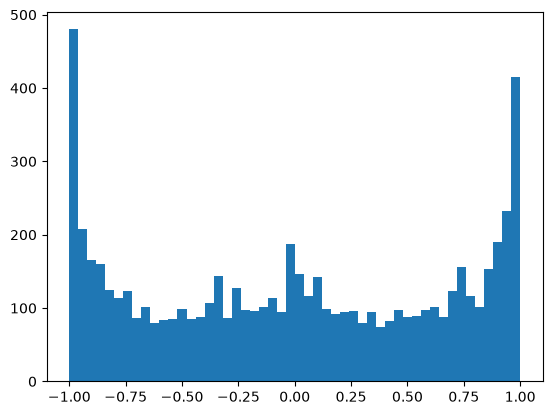

In [21]:
plt.hist(h.view(-1).tolist(), 50)

(array([  3.,   2.,   2.,   7.,   5.,   9.,   6.,  15.,  34.,  38.,  51.,
         69.,  94.,  99., 130., 143., 223., 236., 289., 336., 492., 571.,
        797., 517., 400., 374., 345., 216., 221., 187., 111., 104.,  71.,
         54.,  44.,  26.,  28.,  11.,  10.,  10.,   4.,   7.,   3.,   1.,
          0.,   1.,   1.,   1.,   1.,   1.]),
 array([-5.38547516, -5.1459499 , -4.90642464, -4.66689938, -4.42737411,
        -4.18784885, -3.94832359, -3.70879833, -3.46927307, -3.22974781,
        -2.99022255, -2.75069729, -2.51117203, -2.27164677, -2.03212151,
        -1.79259624, -1.55307098, -1.31354572, -1.07402046, -0.8344952 ,
        -0.59496994, -0.35544468, -0.11591942,  0.12360584,  0.3631311 ,
         0.60265636,  0.84218163,  1.08170689,  1.32123215,  1.56075741,
         1.80028267,  2.03980793,  2.27933319,  2.51885845,  2.75838371,
         2.99790897,  3.23743423,  3.4769595 ,  3.71648476,  3.95601002,
         4.19553528,  4.43506054,  4.6745858 ,  4.91411106,  5.15363632,
 

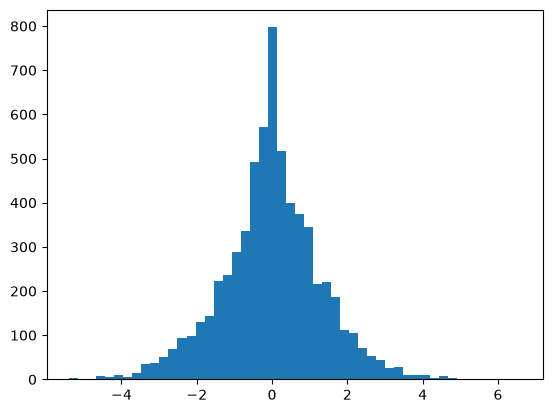

In [22]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [23]:
-torch.tensor(1/27.0).log()

tensor(3.2958)

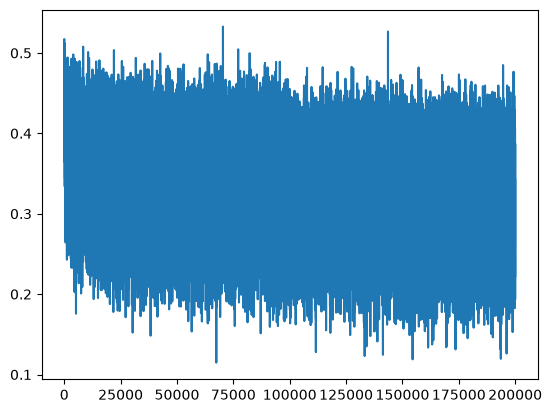

In [24]:
plt.plot(lossi)

In [25]:
with torch.no_grad():
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 # + b1

  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True)

In [27]:
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] 
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1
  # hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0669636726379395
val 2.1023192405700684


In [29]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out = []  
  context = [0] * block_size
  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ W1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
    
  print(''.join(itos[i] for i in out))

claubixambrieliffrglysseffydencessaffrrontaf.
priyah.
prekiennyxabrichaidh.
khleighthbirford.
quintzs.
livwan.
vannirriell.
diarixixfareklivsabrexttzi.
pretts.
hysskyah.
qsiongracsymandrboxbzlejlojnnikonserenzyphnadlymo.
zoeberkliancusnigabriemprrxths.
qlasophsss.
bbdg.
ffreddithphn.
priddgprrtislawnkyciezabruwnydhk.
khlasdantkzamduevz.
khaydyctorroko.
khnykonordngwynlsindzysmatgelizgnnphreschricklystabrielishannardslyothn.
kshantzyah.


### SUMMARY + PYTORCHIFYING
from [mlp2](https://github.com/karpathy/nn-zero-to-hero/blob/master/lectures/makemore/makemore_part3_bn.ipynb)

In [30]:
# Let's train a deeper network
# The classes we create here are the same API as nn.Module in PyTorch

class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647) # for reproducibility

C = torch.randn((vocab_size, n_embd),            generator=g)
layers = [
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size),
]
# layers = [
#   Linear(n_embd * block_size, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, vocab_size),
# ]

with torch.no_grad():
  # last layer: make less confident
  layers[-1].gamma *= 0.1
  #layers[-1].weight *= 0.1
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 1.0 #5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

47024


In [33]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function
  
  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  with torch.no_grad():
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

#   if i >= 1000:
    # break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 2.5356
  10000/ 200000: 2.2481
  20000/ 200000: 2.3801
  30000/ 200000: 1.9018
  40000/ 200000: 2.1323
  50000/ 200000: 2.1383
  60000/ 200000: 1.7381
  70000/ 200000: 1.9834
  80000/ 200000: 2.2764
  90000/ 200000: 1.8918
 100000/ 200000: 1.8508
 110000/ 200000: 1.8354
 120000/ 200000: 1.8027
 130000/ 200000: 1.9075
 140000/ 200000: 1.9338
 150000/ 200000: 2.1322
 160000/ 200000: 2.1914
 170000/ 200000: 2.2092
 180000/ 200000: 1.9086
 190000/ 200000: 1.7646


layer 2 (      Tanh): mean -0.00, std 0.69, saturated: 18.41%
layer 5 (      Tanh): mean -0.02, std 0.74, saturated: 19.97%
layer 8 (      Tanh): mean +0.01, std 0.78, saturated: 19.94%
layer 11 (      Tanh): mean +0.01, std 0.80, saturated: 22.00%
layer 14 (      Tanh): mean +0.03, std 0.82, saturated: 23.81%


/tmp/ipykernel_72045/1397477801.py:7: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))


Text(0.5, 1.0, 'activation distribution')

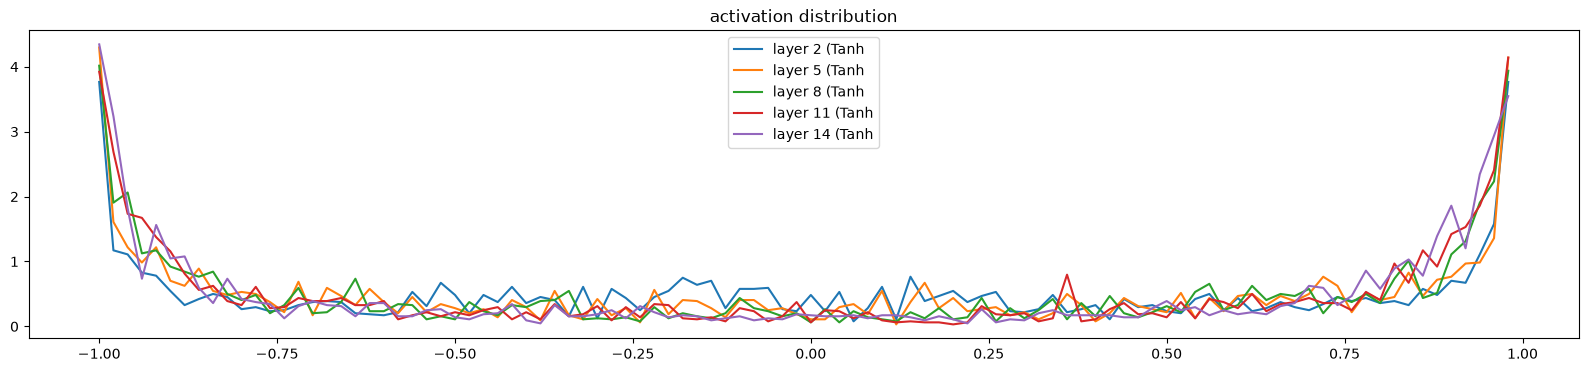

In [34]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean -0.000000, std 4.872169e-03
layer 5 (      Tanh): mean +0.000000, std 3.645669e-03
layer 8 (      Tanh): mean -0.000000, std 3.408452e-03
layer 11 (      Tanh): mean -0.000000, std 3.314432e-03
layer 14 (      Tanh): mean -0.000000, std 4.367461e-03


Text(0.5, 1.0, 'gradient distribution')

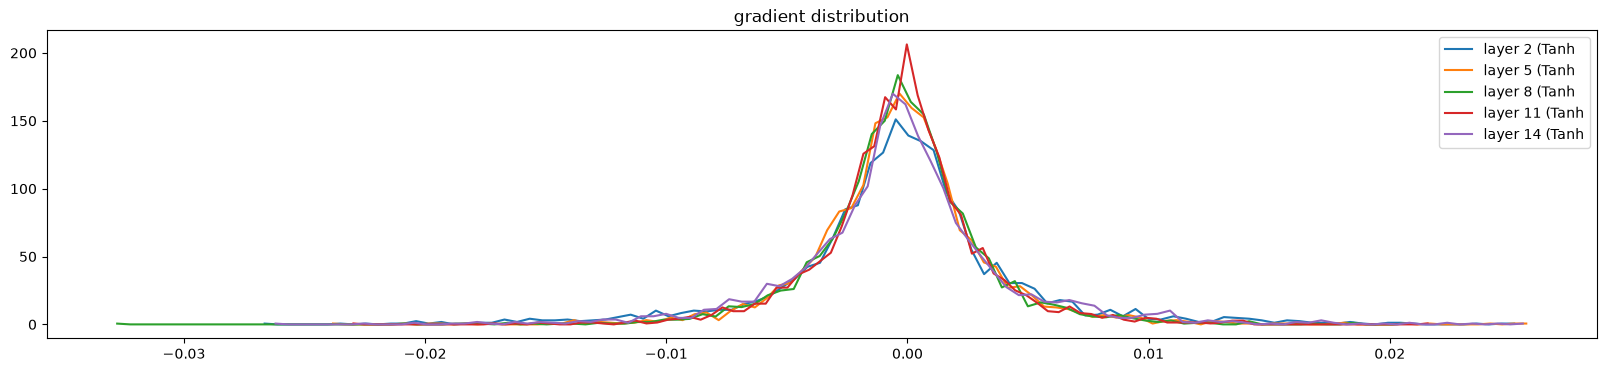

In [35]:

# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 2.596003e-02 | grad:data ratio 2.281134e-02
weight  (30, 100) | mean -0.000196 | std 1.084834e-02 | grad:data ratio 2.696668e-02
weight (100, 100) | mean +0.000012 | std 5.514217e-03 | grad:data ratio 2.257551e-02
weight (100, 100) | mean -0.000008 | std 5.119218e-03 | grad:data ratio 2.123016e-02
weight (100, 100) | mean +0.000068 | std 4.921418e-03 | grad:data ratio 2.132864e-02
weight (100, 100) | mean +0.000026 | std 4.957316e-03 | grad:data ratio 2.294345e-02
weight  (100, 27) | mean +0.000110 | std 1.091172e-02 | grad:data ratio 3.077996e-02


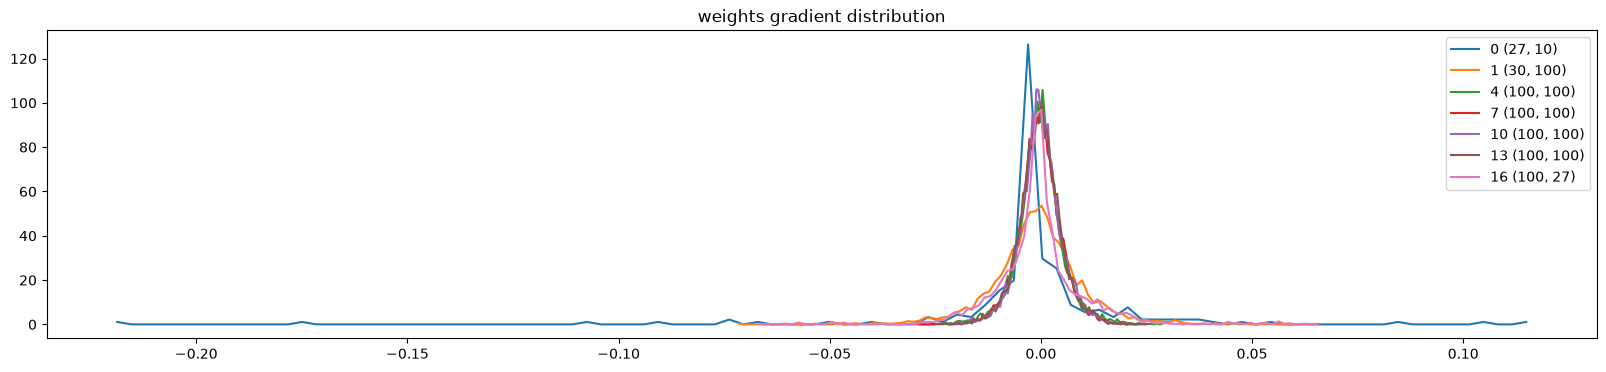

In [36]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

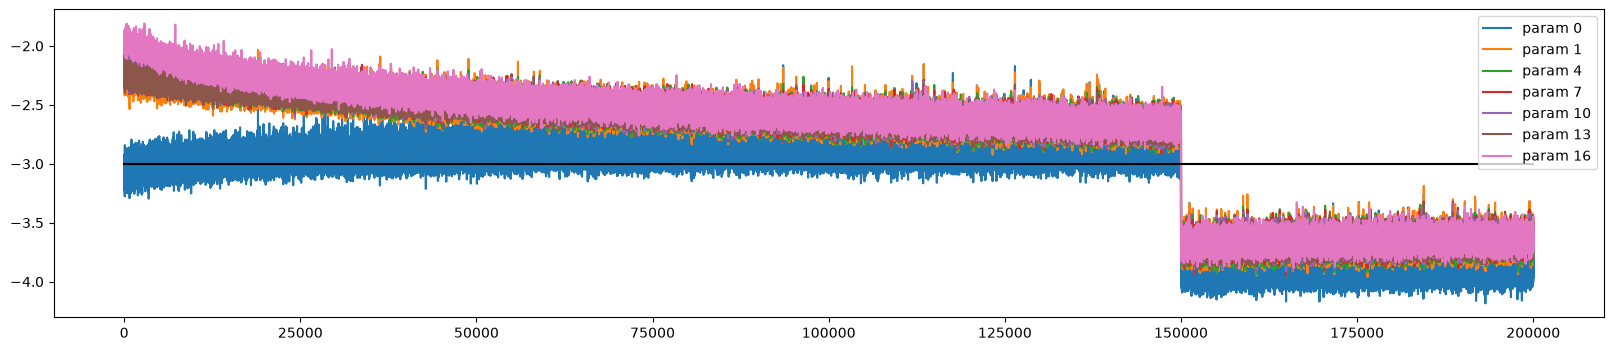

In [ ]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

In [38]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 1.9995648860931396
val 2.077711820602417


In [39]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carmahzato.
harli.
jari.
reity.
skandencer.
hube.
deliah.
jareei.
nellara.
chaiivon.
legend.
brooklyn.
sinthoroine.
liverico.
jermaijaryxin.
kaellissa.
med.
edi.
abette.
hastry.
